In [71]:
#  Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler,LabelEncoder
from sklearn.compose import ColumnTransformer
# from sklearn.pipeline import pipiline
from sklearn.linear_model import LinearRegression

In [72]:
# Load dataset
data=pd.read_csv("house_price_50k.csv")


DATA ANALYSIS

In [73]:
#  shape of dataset
data.shape

(50000, 19)

In [74]:
#  Dataset info
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   area                  50000 non-null  int64  
 1   bedrooms              50000 non-null  int64  
 2   bathrooms             50000 non-null  int64  
 3   floors                50000 non-null  int64  
 4   age                   50000 non-null  int64  
 5   distance              50000 non-null  int64  
 6   garage                50000 non-null  int64  
 7   parking               50000 non-null  int64  
 8   garden                50000 non-null  int64  
 9   security              50000 non-null  int64  
 10  school_nearby         50000 non-null  int64  
 11  hospital_nearby       50000 non-null  int64  
 12  shopping_mall_nearby  50000 non-null  int64  
 13  public_transport      50000 non-null  int64  
 14  crime_rate            50000 non-null  float64
 15  population_density    50000 no

In [75]:
#  First five rows
data.head()

,area,bedrooms,bathrooms,floors,age,distance,garage,parking,garden,security,school_nearby,hospital_nearby,shopping_mall_nearby,public_transport,crime_rate,population_density,location,income_level,price
0,1360,6,2,2,9,10,0,0,1,0,1,0,1,0,6.939333,7242,premium,low,5.952493e+05
1,4272,5,2,3,24,8,1,0,0,1,1,1,1,0,0.400918,7729,low,low,1.571208e+06
2,3592,1,4,3,4,20,0,1,1,1,0,1,0,1,6.292386,1081,premium,mid,1.379943e+06
3,966,5,2,2,6,14,1,0,0,0,0,1,1,0,8.964112,8912,medium,low,4.367819e+05
4,4926,4,3,1,18,9,0,0,0,0,1,0,1,1,2.843309,8146,low,mid,1.792425e+06


In [76]:
#  last five rows
data.tail()

,area,bedrooms,bathrooms,floors,age,distance,garage,parking,garden,security,school_nearby,hospital_nearby,shopping_mall_nearby,public_transport,crime_rate,population_density,location,income_level,price
49995,733,1,4,1,23,23,0,0,1,0,0,1,1,1,1.699633,2188,premium,mid,3.386262e+05
49996,3420,4,1,3,9,13,1,1,1,0,0,0,1,1,9.451960,7273,low,low,1.185043e+06
49997,2218,3,1,2,3,6,0,1,1,0,1,0,0,1,8.659219,9856,medium,mid,8.443978e+05
49998,992,2,4,3,26,20,1,0,0,0,0,0,1,0,6.343849,2858,premium,low,3.796953e+05
49999,3782,1,2,2,5,13,1,0,0,1,1,1,0,0,5.254151,8465,premium,high,1.450285e+06


In [77]:
#  Check impossible values
def CheckImpossible(data):
 BinaryColumn=['garage','parking','garden','security','school_nearby','hospital_nearby','shopping_mall_nearby','public_transport']
 for col in data.select_dtypes(include='number').columns:
    if col in BinaryColumn:
        a=data[col]!=0 
        b=data[col]!=1
        condition=data[col][a][b].count()
        if condition>0:
            print("impossible values for ",col)
            print(data[col][a][b])
        else:continue
        print()
    else:
        a=data[col]<=0
        cond=data[col][a].count()
        if cond>0:
            print("Impossible values for ",col," are ",cond)
            print(data[col][a])
        else:print("No impossible Values for ",col)
        print()


In [78]:
CheckImpossible(data)

No impossible Values for  area

No impossible Values for  bedrooms

No impossible Values for  bathrooms

No impossible Values for  floors

Impossible values for  age  are  1202
22       0
118      0
376      0
412      0
451      0
        ..
49862    0
49876    0
49878    0
49937    0
49945    0
Name: age, Length: 1202, dtype: int64

No impossible Values for  distance

No impossible Values for  crime_rate

No impossible Values for  population_density

No impossible Values for  price



In [79]:
#  Check null Values
data.isnull().sum()

area                    0
bedrooms                0
bathrooms               0
floors                  0
age                     0
distance                0
garage                  0
parking                 0
garden                  0
security                0
school_nearby           0
hospital_nearby         0
shopping_mall_nearby    0
public_transport        0
crime_rate              0
population_density      0
location                0
income_level            0
price                   0
dtype: int64

In [80]:
# check duplicates
data.duplicated().sum()

np.int64(0)

In [81]:
# check data inconsistence
def CheckInconsistence(data):
 for col in data.select_dtypes(include="str").columns:
    print(data[col].value_counts())
    print()


In [82]:
CheckInconsistence(data=data)

location
medium     16755
low        16642
premium    16601
Medium         1
Low            1
Name: count, dtype: int64

income_level
mid     16738
low     16651
high    16611
Name: count, dtype: int64



In [83]:
#  looking for a specific value in
NumInd={
        "Column":[],
        "Index":[],
    }
for col in data.columns:
    for i,num in enumerate(data[col]):
        if num==789:
            NumInd["Column"].append(col)
            NumInd["Index"].append(i)
NumInd=pd.DataFrame(NumInd)

FIXING PROBLEMS

In [84]:
#  fixing impossible values
data.loc[data["age"]<=0,"age"]=np.nan


In [85]:
CheckImpossible(data)

No impossible Values for  area

No impossible Values for  bedrooms

No impossible Values for  bathrooms

No impossible Values for  floors

No impossible Values for  age

No impossible Values for  distance

No impossible Values for  crime_rate

No impossible Values for  population_density

No impossible Values for  price



In [86]:
#  Fixing data inconsistent
for col in data.select_dtypes(include="str").columns:
    data[col]=data[col].str.title()

In [87]:
CheckInconsistence(data=data)

location
Medium     16756
Low        16643
Premium    16601
Name: count, dtype: int64

income_level
Mid     16738
Low     16651
High    16611
Name: count, dtype: int64



In [88]:
#  Fixing null values
data["age"]=data["age"].fillna(data["age"].mode()[0]) # by using mode aggregate funct

ANALYSIS OF DATASET

In [89]:
datanumer=data.drop(["garage","parking","garden","security","school_nearby",'hospital_nearby','shopping_mall_nearby','public_transport'],axis=1)
datanumer.describe()

,area,bedrooms,bathrooms,floors,age,distance,crime_rate,population_density,price
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.00000,5.000000e+04
mean,2752.970540,3.496040,2.498040,1.997060,20.222820,14.968700,5.006444,5065.94598,1.030261e+06
std,1297.148134,1.712146,1.117704,0.815368,11.187232,8.363714,2.876776,2864.34322,4.580199e+05
min,500.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000311,100.00000,9.090069e+04
25%,1630.000000,2.000000,1.000000,1.000000,11.000000,8.000000,2.523018,2575.00000,6.357375e+05
50%,2756.000000,3.000000,2.000000,2.000000,21.000000,15.000000,5.022946,5060.50000,1.031763e+06
75%,3872.000000,5.000000,3.000000,3.000000,30.000000,22.000000,7.479632,7543.00000,1.423102e+06
max,4999.000000,6.000000,4.000000,3.000000,39.000000,29.000000,9.999869,9999.00000,1.996474e+06


In [90]:
# Categorical descriptive
data.describe(include="str")

,location,income_level
count,50000,50000
unique,3,3
top,Medium,Mid
freq,16756,16738


In [91]:
data.head()

,area,bedrooms,bathrooms,floors,age,distance,garage,parking,garden,security,school_nearby,hospital_nearby,shopping_mall_nearby,public_transport,crime_rate,population_density,location,income_level,price
0,1360,6,2,2,9.0,10,0,0,1,0,1,0,1,0,6.939333,7242,Premium,Low,5.952493e+05
1,4272,5,2,3,24.0,8,1,0,0,1,1,1,1,0,0.400918,7729,Low,Low,1.571208e+06
2,3592,1,4,3,4.0,20,0,1,1,1,0,1,0,1,6.292386,1081,Premium,Mid,1.379943e+06
3,966,5,2,2,6.0,14,1,0,0,0,0,1,1,0,8.964112,8912,Medium,Low,4.367819e+05
4,4926,4,3,1,18.0,9,0,0,0,0,1,0,1,1,2.843309,8146,Low,Mid,1.792425e+06


DETERMINING FEATURE IMPORTANT

WHETHER A CATEGORICAL FEATURE AFFECTS TARGET

In [95]:
#  Function to check whether a certain categorical column affect price of house
# implementing t-test
def t_test_2samp(n1,n2,x1,x2,s1,s2,varicol,targcol,t_critical=1.960):
    meandiff=x1-x2
    stderr1=((s1**2))/n1
    stderr2=((s2**2))/n2
    sumstderr=stderr1+stderr2
    t_calc=round(abs(meandiff/((sumstderr**0.5))),2)
    print(f"""t_calc {t_calc}
t_critical {t_critical}""")
    if t_critical<t_calc:
        print("Null Hypothesis is rejected")
        print(f"{varicol} variable affects {targcol}")
    else:
        print("Null Hypothesis accepted")
        print(f"{varicol} has no effect on {targcol}")

In [96]:
#  loop 
for col in data.select_dtypes(include="str").columns:
    n1,n2,n3=data.groupby(col)["price"].count()
    x1,x2,x3=data.groupby(col)["price"].mean()
    s1,s2,s3=data.groupby(col)["price"].std()
    t_test_2samp(
    n1=n1,
    n2=n3,
    x1=x1,
    x2=x3,
    s1=s1,
    s2=s3,
    varicol=col,
    targcol="Price of House")
    print()


t_calc 16.67
t_critical 1.96
Null Hypothesis is rejected
location variable affects Price of House

t_calc 4.91
t_critical 1.96
Null Hypothesis is rejected
income_level variable affects Price of House



RELATION BETWEEN NUMERICAL FEATURE AND PRICE OF HOUSE

In [98]:
numericcolumn=[]
for col in datanumer.select_dtypes(include="str").columns:
    numericcolumn.append(col)
datanum=datanumer.drop(numericcolumn,axis=1)
corr=datanum.corr()


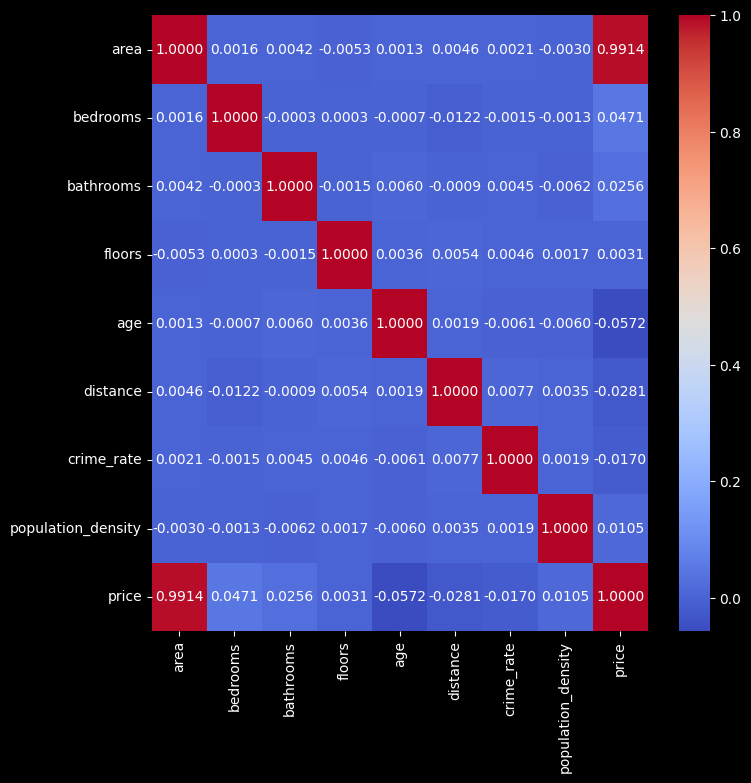

In [99]:
plt.figure(figsize=(8,8))
sns.heatmap(
    corr,
    annot=True,
    fmt='.4f',
    cmap="coolwarm"
)
plt.show()

BINARY NUMERICAL FEATURES VERSUS PRICE OF HOUSE

In [100]:
binnumer=data[["garage","parking","garden","security","school_nearby",'hospital_nearby','shopping_mall_nearby','public_transport','price']]
bcorr=binnumer.corr()

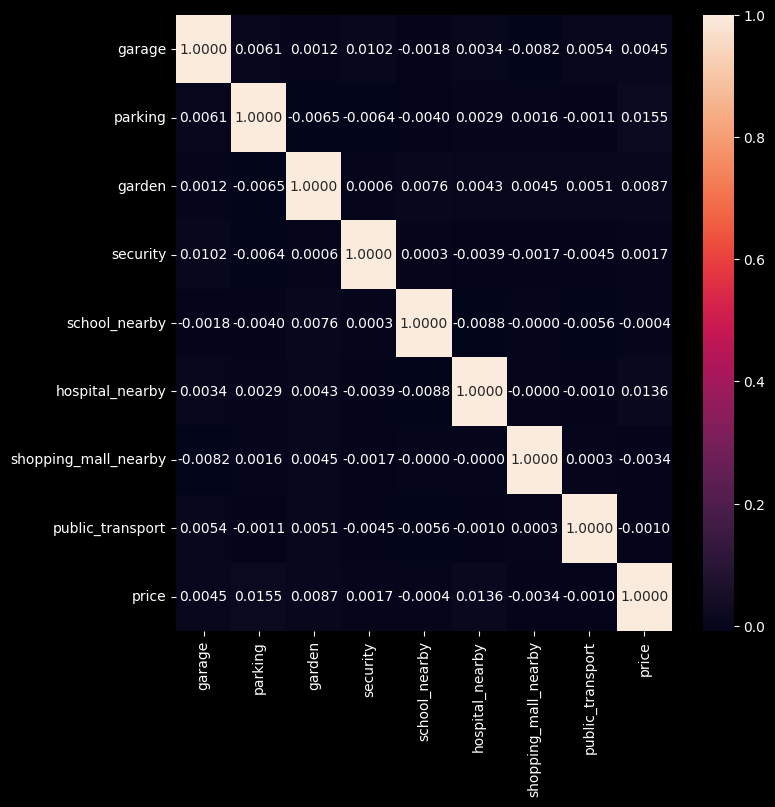

In [101]:
plt.figure(figsize=(8,8))
sns.heatmap(
    bcorr,
    annot=True,
    fmt=".4f"
)
plt.show()